# ChartQA bake-off: Qwen2.5-VL-3B vs Gemma 3 4B

**Track A capstone — base-model selection, measured rather than argued.**

Three steps:

1. **Evaluate both models cold** on the *human-annotated* ChartQA test questions. No training.
2. **Fine-tune the promising candidate(s)** on ~200 examples and re-measure.
3. **Choose** on the measured delta, not on the published number.

### Why human-annotated only

ChartQA ships 9,608 human-written questions and 23,111 generated from chart summaries by a T5
model. The two halves are not the same task. Published per-split scores for Qwen2.5-VL:

| Split | Relaxed accuracy |
|---|---|
| Augmented (machine-generated) | 93.76 |
| **Human-written** | **78.96** |
| Reported average | 86.36 |

The commonly-quoted ~84–86 average is carried by the easy half. This notebook filters
`human_or_machine == 0` everywhere, so every number here is a human-split number and is **not**
comparable to a published average.

### What decides the outcome

Step 1 tells you where each model starts. **Step 1 alone cannot pick a winner** — a low score may
mean missing capability (trainable) or a vision encoder that cannot resolve tick labels
(not trainable). Step 2 is the test that separates those two, which is why it exists.

---

### Hardware: read this before picking a runtime

**Gemma 3 requires bf16.** It was trained on TPUs and its activations exceed fp16's ceiling of
65,504, so on fp16-only hardware it emits NaNs, empty strings or nonsense. That is not a crash you
would notice — it is a near-zero score that reads as "Gemma is bad at charts" when it is really
numerical overflow. **The notebook therefore refuses to score Gemma without bf16** rather than
publishing a number it cannot stand behind.

| Runtime | bf16 | VRAM | Verdict |
|---|---|---|---|
| **Colab T4** (Turing, sm_75) | **No** | 16 GB | Qwen only. Cannot produce the comparison. |
| **Colab L4** (Ada, sm_89) | Yes | 24 GB | **Recommended on Colab.** Both models, comfortably. |
| **Colab A100** (Ampere, sm_80) | Yes | 40 GB | Works; more than needed. |
| **Local RTX 40/50-series** (Ada / Blackwell) | Yes | 8-16 GB | **Works** - the notebook drops to 4-bit. See below. |
| Course SSH GPU machine | check | check | Run the environment cell and read what it prints. |

**Switching runtimes needs no code edits.** The environment cell reads the card and picks the
precision, resolution and batch size that fit it. Each run writes to its own tagged folder under
`bakeoff_out/` (`l4_bf16`, `5070-ti_4bit`, `t4_fp16`) and records an `environment` block in its
summary, so two runs on two machines never get mistaken for each other.

To compare across machines rather than just within one, set `CONFIG["FORCE_EVAL_4BIT"] = True` on
the larger card. That reproduces the small card's precision deliberately, which is the only way
its numbers and an L4's are the same experiment.

On Colab: **Runtime -> Change runtime type -> L4 GPU**. L4 is a paid tier - roughly $0.17/hr of
compute units against T4's $0.12/hr. The whole bake-off is about an hour, so the difference is
cents, and **a T4 cannot produce this answer at any price**.

With only a T4, run it anyway: you get a valid Qwen baseline and a valid Qwen fine-tune delta, and
the notebook states plainly that the Gemma half is missing rather than filling it with a bad number.

### Running on a local RTX laptop or workstation (12-16 GB)

A consumer RTX 40- or 50-series card **has bf16**, so unlike a T4 it can produce the whole
comparison. The constraint is capacity, not numerics, and capacity is solvable.

Twelve gigabytes will not hold Gemma 3 4B in bf16 (about 8.6 GB of weights) plus a 896x896
pan-and-scan activation stack, and on Windows the desktop compositor holds back roughly a further
gigabyte. So below 14 GB the environment cell switches **Step 1 to 4-bit NF4 for both models**.

That is a deliberate trade, and it is worth being precise about what it costs:

- **The comparison stays valid.** Both models are quantised identically, with the same NF4 recipe
  and the same compute dtype. The ranking is what Step 1 is for, and quantisation does not
  reorder two models that are more than a couple of points apart.
- **The absolute number drops slightly** - typically one to three points below bf16. So a 4-bit
  Qwen score is not comparable to the published 78.96, and the notebook says so where it prints
  the comparison.
- **Label it.** If these are the numbers that reach the report, they are "4-bit NF4, 0.50M pixels",
  not "relaxed accuracy". Step 2 was always going to be 4-bit anyway, so the fine-tune delta - the
  number that actually decides the model - is unaffected by this.

**Blackwell (RTX 50-series) needs a CUDA 12.8 build of PyTorch.** A default `pip install torch` may
still fetch a cu124-era wheel, which has no sm_120 kernels and fails at the first matmul with
`CUDA error: no kernel image is available for execution on the device`. The environment cell checks
for this before you waste a model download:

```
pip install --index-url https://download.pytorch.org/whl/cu128 torch torchvision
pip install -U "transformers>=4.50" datasets accelerate "peft>=0.11" "bitsandbytes>=0.45"
```

Ada (RTX 40-series) is fine on any recent stable wheel. On Windows, `bitsandbytes` has had native
wheels since 0.43, so WSL is optional; flash-attention is not available either way, which is why
every adapter here already loads with `attn_implementation="eager"`. Close other GPU applications
before the run - a browser with hardware acceleration on can cost a gigabyte.

### Other prerequisites

The first code cell installs everything on Colab and prints the exact command for a local
environment. **A preflight cell then verifies the lot** - versions, the two model classes actually
importing, free disk, and Gemma licence acceptance - and refuses to continue if anything is wrong.

| Package | Minimum | Why |
|---|---|---|
| `torch` | CUDA 12.8 build on Blackwell | sm_120 kernels; see above |
| `transformers` | 4.50 | `Gemma3ForConditionalGeneration` first ships here |
| `bitsandbytes` | 0.45 (Blackwell) / 0.43 | 4-bit NF4; 0.45 added sm_120 |
| `peft` | 0.11 | LoRA for Step 2 |
| `accelerate` | 0.30 | `device_map` placement |
| `datasets` | 2.19 | ChartQA loader |
| `sentencepiece`, `pillow`, `huggingface_hub`, `pandas` | any recent | tokeniser, image decode, gated auth, tables |

**`google/gemma-3-4b-it` is gated.** Accept the licence on the model page, then
`huggingface-cli login`. The preflight cell checks this before anything downloads - otherwise it
401s at Gemma load, which is after Qwen has already run and the notebook looks healthy.

Budget **~30 GB of free disk** for the Hugging Face cache (both models plus the ChartQA images).


In [1]:
# --- Dependencies. Run this first, then RESTART THE KERNEL ------------------
# Colab's preinstalled transformers is too old for Gemma 3, so this installs by
# default there. Locally you manage your own environment, so it is opt-in: set
# RUN_INSTALL = True once, or run the printed command in your shell.
import sys, subprocess

IN_COLAB = "google.colab" in sys.modules
RUN_INSTALL = IN_COLAB          # <- set True to install into a local kernel

# torch is deliberately NOT in this list: the right wheel depends on your CUDA,
# and letting pip resolve it can silently replace a working build with one that
# has no kernels for your card.
PACKAGES = [
    "transformers>=4.50",     # Gemma3ForConditionalGeneration first appears here
    "datasets>=2.19",
    "accelerate>=0.30",
    "peft>=0.11",             # LoRA for Step 2
    "bitsandbytes>=0.45",     # >=0.45 carries Blackwell/sm_120 kernels
    "sentencepiece",          # Gemma tokenizer
    "pillow>=10.0",           # dataset image decoding
    "huggingface_hub>=0.26",  # gated-repo auth for Gemma
    "pandas",
]

if RUN_INSTALL:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-U"] + PACKAGES)
    print()
    print("=" * 70)
    print("Installed. Now RESTART THE KERNEL.")
    print("  Colab:   Runtime > Restart session")
    print("  Jupyter: Kernel > Restart Kernel")
    print("Then run from the NEXT cell down - do not re-run this one.")
    print("Without the restart the old transformers stays loaded in memory and")
    print("Gemma 3 fails to import even though the new version is on disk.")
    print("=" * 70)
else:
    print("Local environment - not installing anything.")
    print("The preflight cell below checks every package and tells you what is")
    print("missing. To install it all up front:")
    print()
    print("  pip install -U " + " ".join('"%s"' % p for p in PACKAGES))
    print()
    print("Install torch separately, matched to your GPU:")
    print("  RTX 50-series / Blackwell (sm_120) - CUDA 12.8 build is REQUIRED:")
    print("    pip install --index-url https://download.pytorch.org/whl/cu128 \\")
    print("                torch torchvision")
    print("  RTX 40-series and older: 'pip install torch torchvision' is fine.")
    print()
    print("Gemma is a gated repo. Accept the licence at")
    print("  https://huggingface.co/google/gemma-3-4b-it")
    print("then authenticate:  huggingface-cli login")


Local environment - not installing anything.
The preflight cell below checks every package and tells you what is
missing. To install it all up front:

  pip install -U "transformers>=4.50" "datasets>=2.19" "accelerate>=0.30" "peft>=0.11" "bitsandbytes>=0.45" "sentencepiece" "pillow>=10.0" "huggingface_hub>=0.26" "pandas"

Install torch separately, matched to your GPU:
  RTX 50-series / Blackwell (sm_120) - CUDA 12.8 build is REQUIRED:
    pip install --index-url https://download.pytorch.org/whl/cu128 \
                torch torchvision
  RTX 40-series and older: 'pip install torch torchvision' is fine.

Gemma is a gated repo. Accept the licence at
  https://huggingface.co/google/gemma-3-4b-it
then authenticate:  huggingface-cli login


## 0. Configuration

Every knob that changes a result lives here, so the notebook can be re-run reproducibly and the
settings can be pasted into the report.

In [2]:
from huggingface_hub import login

login(token="hf_<your_token_here>")

In [3]:
CONFIG = {
    # --- data -------------------------------------------------------------
    "DATASET": "HuggingFaceM4/ChartQA",
    "N_EVAL": 150,          # held-out test questions, human-written only
    "N_TRAIN": 200,         # Step 2 fine-tune set, drawn from the TRAIN split
    "N_VAL": 40,            # watched during fine-tuning, never scored for the headline
    "SEED": 42,

    # --- models -----------------------------------------------------------
    "QWEN_ID":  "Qwen/Qwen2.5-VL-3B-Instruct",
    "GEMMA_ID": "google/gemma-3-4b-it",

    # Qwen has a dynamic-resolution encoder, so this is the dominant cost lever.
    # ~1.3M pixels is deliberately higher than a document task needs: charts are
    # read at the tick label. Lower it first if you hit OOM.
    "QWEN_MAX_PIXELS": 1280 * 28 * 28,   # ~1.00M px; raise to 1600*28*28 for ~1.25M
    "QWEN_MIN_PIXELS": 256 * 28 * 28,
    # Gemma 3's SigLIP encoder is fixed at 896x896 with pan-and-scan. Nothing to set.

    # --- generation -------------------------------------------------------
    "MAX_NEW_TOKENS": 32,   # answers are short; a long budget only invites prose
    "BATCH_SIZE": 4,        # eval batch; drop to 1 if memory is tight

    # --- step 2 fine-tune -------------------------------------------------
    "LORA_R": 16,
    "LORA_ALPHA": 32,
    "LORA_DROPOUT": 0.05,
    "LR": 1e-4,
    "EPOCHS": 2,            # 200 examples: 2 epochs is a smoke test, not a result
    "GRAD_ACCUM": 8,
    "MICRO_BATCH": 1,

    # --- decision rule ----------------------------------------------------
    # Step 2 must beat its own 4-bit pre-finetune baseline by at least this many
    # points to count as "the model can be taught". Set from the bootstrap CI at
    # n=150, which is roughly +-6 points -- so a 3-point move on 150 examples is
    # suggestive, not significant, and the notebook says so.
    "MIN_MEANINGFUL_DELTA": 3.0,

    # --- run control ------------------------------------------------------
    # Fine-tune every model Step 1 scored, not just the leader. A model 20 points
    # behind cold is exactly the one worth training: Step 2 is what separates
    # "missing capability, teachable" from "the encoder cannot read tick labels".
    "TRAIN_BOTH": True,
    "CANDIDATE_WINDOW": 15.0,   # only used when TRAIN_BOTH is False

    # Skip work already on disk. After a crash or a restart, re-running from the
    # top picks up where it stopped instead of repeating finished evaluations.
    "RESUME": True,

    # How many OOM-skipped batches to tolerate before calling it a bad config
    # rather than an awkward example.
    "MAX_OOM_SKIPS": 5,

    # A 4-minute proof that the machine survives sustained load before you spend
    # 40. Writes to its own directory so it can never be mistaken for a result.
    "SMOKE_TEST": False,

    # None = decide from VRAM. True/False overrides it. Set True on a big card
    # to reproduce a small card's numbers exactly; the only way two runs on
    # different hardware are comparable is if they used the same precision.
    "FORCE_EVAL_4BIT": None,

    "OUT_DIR": "bakeoff_out",
}

import os, json, pathlib
pathlib.Path(CONFIG["OUT_DIR"]).mkdir(exist_ok=True)
print(json.dumps(CONFIG, indent=2))


{
  "DATASET": "HuggingFaceM4/ChartQA",
  "N_EVAL": 150,
  "N_TRAIN": 200,
  "N_VAL": 40,
  "SEED": 42,
  "QWEN_ID": "Qwen/Qwen2.5-VL-3B-Instruct",
  "GEMMA_ID": "google/gemma-3-4b-it",
  "QWEN_MAX_PIXELS": 1003520,
  "QWEN_MIN_PIXELS": 200704,
  "MAX_NEW_TOKENS": 32,
  "BATCH_SIZE": 4,
  "LORA_R": 16,
  "LORA_ALPHA": 32,
  "LORA_DROPOUT": 0.05,
  "LR": 0.0001,
  "EPOCHS": 2,
  "GRAD_ACCUM": 8,
  "MICRO_BATCH": 1,
  "MIN_MEANINGFUL_DELTA": 3.0,
  "TRAIN_BOTH": true,
  "CANDIDATE_WINDOW": 15.0,
  "RESUME": true,
  "MAX_OOM_SKIPS": 5,
  "SMOKE_TEST": false,
  "FORCE_EVAL_4BIT": null,
  "OUT_DIR": "bakeoff_out"
}


In [4]:
import gc, os, re, sys, time, random, math

# Fragmentation, not raw capacity, is what usually ends a two-model run: loading
# and freeing several GB twice leaves the allocator holding gaps too small to
# reuse. expandable_segments grows one region instead of many fixed blocks.
# Must be set before the CUDA context exists, hence above "import torch".
# Unsupported platforms ignore it with a warning; nothing breaks.
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import torch
import pandas as pd
from datasets import load_dataset
from transformers import AutoProcessor, BitsAndBytesConfig

random.seed(CONFIG["SEED"])
torch.manual_seed(CONFIG["SEED"])

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
assert DEVICE == "cuda", (
    "No GPU. On Colab: Runtime > Change runtime type > GPU "
    "(L4 preferred; T4 works for Qwen only)."
)

CAP = torch.cuda.get_device_capability(0)
GPU_NAME = torch.cuda.get_device_name(0)
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
HAS_BF16 = torch.cuda.is_bf16_supported()
DTYPE = torch.bfloat16 if HAS_BF16 else torch.float16

print("gpu          ", GPU_NAME, "(sm_%d%d)" % CAP)
print("vram         ", round(VRAM_GB, 1), "GB")
print("bf16         ", HAS_BF16)
print("dtype        ", DTYPE)

# --- does this torch build actually have kernels for this card? -------------
# A fresh RTX 50-series card with a cu124-era wheel reports fine here and then
# dies at the first matmul with "no kernel image is available". Catch it now,
# before a 9 GB model download.
def _arch_supported(cap, archs):
    major, minor = cap
    for a in archs:
        digits = "".join(ch for ch in a[3:] if ch.isdigit())
        if not a.startswith("sm_") or not digits:
            continue
        if int(digits[:-1]) == major and int(digits[-1]) <= minor:
            return True
    return False

ARCH_LIST = list(torch.cuda.get_arch_list())
if not _arch_supported(CAP, ARCH_LIST):
    raise RuntimeError(
        "This torch build has no kernels for sm_%d%d.\n"
        "  torch      : %s\n"
        "  built for  : %s\n"
        "Install a CUDA 12.8 build:\n"
        "  pip install --index-url https://download.pytorch.org/whl/cu128 "
        "torch torchvision" % (CAP[0], CAP[1], torch.__version__, ", ".join(ARCH_LIST))
    )

# --- the gate that keeps a bad number out of the results --------------------
# Gemma 3 was trained in bf16 on TPUs. Its activations exceed fp16's 65,504
# ceiling, so without bf16 it returns NaN or empty output. Scoring that would
# produce a near-zero that reads as a capability finding and is not one.
GEMMA_RUNNABLE = HAS_BF16

if not GEMMA_RUNNABLE:
    print()
    print("!" * 70)
    print("GEMMA 3 WILL BE SKIPPED: this GPU has no bf16 support.")
    print()
    print("  Gemma 3 is numerically unstable in fp16 - it returns NaN or empty")
    print("  output. That scores near zero and looks like a real result.")
    print("  Publishing it would be worse than publishing nothing.")
    print()
    print("  For the full comparison: Runtime > Change runtime type > L4 GPU.")
    print("  Continuing now still gives a valid Qwen baseline and delta.")
    print("!" * 70)

# --- auto-tune for the card we actually got ---------------------------------
# EVAL_4BIT quantises *both* models in Step 1. It costs a point or two of
# absolute accuracy and keeps the comparison honest, because both sides get the
# identical NF4 recipe. Step 2 was always 4-bit, so the delta is unaffected.
EVAL_4BIT = VRAM_GB < 14
if CONFIG.get("FORCE_EVAL_4BIT") is not None:
    EVAL_4BIT = bool(CONFIG["FORCE_EVAL_4BIT"])
    print()
    print("FORCE_EVAL_4BIT is set: Step 1 precision is %s by request, not by VRAM."
          % ("4-bit NF4" if EVAL_4BIT else str(DTYPE)))

if VRAM_GB < 14:
    CONFIG["QWEN_MAX_PIXELS"] = 640 * 28 * 28      # ~0.50M px, down from ~1.00M
    CONFIG["BATCH_SIZE"] = 1
    CONFIG["GRAD_CHECKPOINTING"] = True
    print()
    print("Tight-VRAM profile applied (%.1f GB):" % VRAM_GB)
    print("  EVAL_4BIT       -> True  (Step 1 runs 4-bit NF4 for BOTH models)")
    print("  QWEN_MAX_PIXELS -> %d (~%.2fM px)"
          % (CONFIG["QWEN_MAX_PIXELS"], CONFIG["QWEN_MAX_PIXELS"] / 1e6))
    print("  BATCH_SIZE      -> 1")
    print("  gradient checkpointing enabled for Step 2")
    print()
    print("  Gemma 3 4B needs ~8.6 GB of bf16 weights before activations, which")
    print("  does not fit here. 4-bit does. Report these as '4-bit NF4' scores -")
    print("  they are NOT comparable to the published 78.96 bf16 figure.")
elif VRAM_GB < 20:
    CONFIG["QWEN_MAX_PIXELS"] = 640 * 28 * 28
    CONFIG["BATCH_SIZE"] = 1
    CONFIG["GRAD_CHECKPOINTING"] = True
    print()
    print("Small-VRAM profile applied (%.1f GB):" % VRAM_GB)
    print("  QWEN_MAX_PIXELS -> %d (~%.2fM px)"
          % (CONFIG["QWEN_MAX_PIXELS"], CONFIG["QWEN_MAX_PIXELS"] / 1e6))
    print("  BATCH_SIZE      -> 1")
    print("  gradient checkpointing enabled for Step 2")
else:
    CONFIG["GRAD_CHECKPOINTING"] = False
    print()
    print("Full profile (%.1f GB): no downscaling, no gradient checkpointing." % VRAM_GB)
    print("  QWEN_MAX_PIXELS -> %d (~%.2fM px)"
          % (CONFIG["QWEN_MAX_PIXELS"], CONFIG["QWEN_MAX_PIXELS"] / 1e6))
    print("  BATCH_SIZE      -> %d" % CONFIG["BATCH_SIZE"])
    print("  Step 1 precision-> %s" % ("4-bit NF4" if EVAL_4BIT else str(DTYPE)))
    print("  These are the numbers that can be set beside the published 78.96.")

if VRAM_GB < 20:
    print()
    print("  NB: lower resolution is itself a confound. Charts are read at the")
    print("  tick label, so this is a floor on the model, not its ceiling.")
    print("  Say so in the report if these are the numbers you publish.")

if sys.platform == "win32":
    print()
    print("  Windows: the desktop compositor reserves ~1 GB of this card, so")
    print("  usable VRAM is below the nameplate figure. Close other GPU apps.")


# --- keep runs from different machines apart --------------------------------
# Two runs on two cards are two different experiments. Writing them to the same
# filenames silently replaces one with the other, and the surviving file gives
# no hint which card produced it.
_drop = {"nvidia", "geforce", "laptop", "gpu", "tesla", "rtx"}
_slug = "-".join(w for w in GPU_NAME.lower().replace("-", " ").split() if w not in _drop)
_slug = "".join(ch for ch in _slug if ch.isalnum() or ch == "-") or "gpu"
RUN_TAG = "%s_%s" % (_slug, "4bit" if EVAL_4BIT else "bf16" if HAS_BF16 else "fp16")

if CONFIG["SMOKE_TEST"]:
    CONFIG["N_EVAL"] = 20
    CONFIG["N_TRAIN"] = 50
    CONFIG["EPOCHS"] = 1
    RUN_TAG += "_smoke"
    print()
    print("SMOKE TEST: N_EVAL -> 20, N_TRAIN -> 50, EPOCHS -> 1, BOTH models.")
    print("  This is a memory and stability rehearsal of the full path, not a")
    print("  measurement: every model gets loaded, fine-tuned and released in")
    print("  the same order as the real run, just on tiny data.")
    print("  Output goes to a _smoke directory, so these numbers can never be")
    print("  picked up as real ones. Set SMOKE_TEST = False for the real run.")

ENVIRONMENT = {
    "run_tag": RUN_TAG,
    "gpu": GPU_NAME,
    "compute_capability": "sm_%d%d" % CAP,
    "vram_gb": round(VRAM_GB, 1),
    "torch": torch.__version__,
    "bf16_supported": HAS_BF16,
    "step1_precision": "4-bit NF4" if EVAL_4BIT else str(DTYPE),
    "qwen_max_pixels": CONFIG["QWEN_MAX_PIXELS"],
    "eval_batch_size": CONFIG["BATCH_SIZE"],
    "gemma_scored": GEMMA_RUNNABLE,
}

CONFIG["OUT_DIR"] = os.path.join("bakeoff_out", RUN_TAG)
pathlib.Path(CONFIG["OUT_DIR"]).mkdir(parents=True, exist_ok=True)
print()
print("run tag      ", RUN_TAG)
print("output dir   ", CONFIG["OUT_DIR"])


def vram_free_gb():
    # Device-level free memory, so it accounts for the desktop compositor and
    # any other process on the card - not just this allocator's view.
    return torch.cuda.mem_get_info()[0] / 1e9


def require_vram(need_gb, phase):
    """Fail before a load that cannot fit, instead of part-way through it."""
    free = vram_free_gb()
    print("  vram: %.1f GB free, ~%.1f GB needed for %s" % (free, need_gb, phase))
    if free < need_gb:
        raise RuntimeError(
            "Only %.1f GB free but %s needs ~%.1f GB.\n"
            "  - a previous model may still be referenced (see free_memory warnings)\n"
            "  - close other GPU applications\n"
            "  - or restart the kernel and re-run; RESUME skips finished work"
            % (free, phase, need_gb))


def free_memory(*objs, **kw):
    """Release GPU memory and REPORT whether it actually worked.

    Passing objects here cannot free them: `del o` drops this function's local
    name, not the caller's. The caller must null its own binding first --

        adapter = None
        free_memory()

    -- which is exactly the mistake this function used to hide, letting two
    models co-reside while the second loaded. The warning below makes a missed
    reference visible instead of turning it into an OOM three minutes later.
    """
    before = torch.cuda.memory_allocated() / 1e9
    for o in objs:
        del o
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()
    after = torch.cuda.memory_allocated() / 1e9
    if not kw.get("quiet"):
        print("  freed %.2f GB -> %.2f GB still allocated, %.1f GB free on device"
              % (before - after, after, vram_free_gb()))
    if after > 1.0:
        print("  WARNING: %.2f GB is still held by a live reference. Set the"
              " variable to None before calling free_memory()." % after)
    return after


def vram_peak_gb():
    return round(torch.cuda.max_memory_allocated() / 1e9, 2)


def set_use_cache(model, value):
    """Set use_cache everywhere it actually lives, and report what changed.

    Qwen2.5-VL and Gemma 3 are composite models: the top-level config wraps a
    nested text config, and the decoder reads the nested one. Setting only
    `model.config.use_cache` therefore looks correct and does nothing, which is
    why "use_cache=True is incompatible with gradient checkpointing" still
    appears. Transformers overrides it locally so training is correct either
    way -- but a line that appears to do something and does not is worse than
    no line, because it stops anyone looking further.
    """
    touched = []
    seen = set()
    targets = [("config", getattr(model, "config", None))]
    cfg = getattr(model, "config", None)
    for name in ("text_config", "vision_config", "llm_config"):
        targets.append((name, getattr(cfg, name, None)))
    targets.append(("generation_config", getattr(model, "generation_config", None)))

    for name, obj in targets:
        if obj is None or id(obj) in seen:
            continue
        seen.add(id(obj))
        if hasattr(obj, "use_cache"):
            obj.use_cache = value
            touched.append(name)
    return touched



def sane_output(rows, label):
    # Catch a numerical blow-up before it becomes a published score. A model
    # returning mostly empty strings or 'nan' is broken, not bad - and the
    # difference between those two is the whole point of this notebook.
    empties = sum(1 for r in rows if not r["pred"].strip())
    nans = sum(1 for r in rows if "nan" in r["raw_output"].lower())
    rate = 100.0 * (empties + nans) / max(len(rows), 1)
    if rate > 30.0:
        print()
        print("  WARNING [%s]: %.0f%% of outputs are empty or NaN." % (label, rate))
        print("  That is a numerical failure, not a low score. Do not report it")
        print("  as a capability measurement - check dtype and bf16 support.")
        return False
    return True


gpu           NVIDIA GeForce RTX 5070 Ti Laptop GPU (sm_120)
vram          12.8 GB
bf16          True
dtype         torch.bfloat16

Tight-VRAM profile applied (12.8 GB):
  EVAL_4BIT       -> True  (Step 1 runs 4-bit NF4 for BOTH models)
  QWEN_MAX_PIXELS -> 501760 (~0.50M px)
  BATCH_SIZE      -> 1
  gradient checkpointing enabled for Step 2

  Gemma 3 4B needs ~8.6 GB of bf16 weights before activations, which
  does not fit here. 4-bit does. Report these as '4-bit NF4' scores -
  they are NOT comparable to the published 78.96 bf16 figure.

  NB: lower resolution is itself a confound. Charts are read at the
  tick label, so this is a floor on the model, not its ceiling.
  Say so in the report if these are the numbers you publish.

  Windows: the desktop compositor reserves ~1 GB of this card, so
  usable VRAM is below the nameplate figure. Close other GPU apps.

run tag       5070-ti_4bit
output dir    bakeoff_out\5070-ti_4bit


In [5]:
CONFIG["QWEN_MAX_PIXELS"] = 1280 * 28 * 28   # undo the tight-VRAM throttle;
CONFIG["OUT_DIR"] = "bakeoff_out/5070-ti_qwen_1M"   # Qwen peaked at 3.53/12.8 GB

### Preflight

Every check below maps to a failure that otherwise surfaces **after** a multi-gigabyte download:
a stale `transformers` at model import, an unaccepted licence at Gemma load, a full disk part-way
through a shard. Thirty seconds here saves twenty minutes there.


In [6]:
import shutil
from importlib.metadata import version, PackageNotFoundError

def _installed(pkg):
    try:
        return version(pkg)
    except PackageNotFoundError:
        return None

def _as_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out)

# bitsandbytes only needs >=0.45 on Blackwell; older cards are fine on 0.43.
_BNB_MIN = "0.45" if CAP[0] >= 12 else "0.43"

REQUIRED = [
    ("transformers",    "4.50"),
    ("datasets",        "2.19"),
    ("accelerate",      "0.30"),
    ("peft",            "0.11"),
    ("bitsandbytes",    _BNB_MIN),
    ("sentencepiece",   None),
    ("pillow",          None),
    ("huggingface_hub", "0.26"),
    ("pandas",          None),
]

problems = []
print("  %-18s %-13s %-9s" % ("package", "installed", "needs"))
print("  " + "-" * 46)
for pkg, minv in REQUIRED:
    have = _installed(pkg)
    ok = have is not None and (minv is None or _as_tuple(have) >= _as_tuple(minv))
    print("  %-18s %-13s %-9s %s"
          % (pkg, have or "MISSING", minv or "any", "" if ok else "<-- FIX"))
    if not ok:
        problems.append(pkg if minv is None else pkg + ">=" + minv)

# A version string can look new enough while the import still fails, so prove it.
try:
    from transformers import Gemma3ForConditionalGeneration, Qwen2_5_VLForConditionalGeneration
    print("\n  model classes    import cleanly")
except ImportError as e:
    problems.append("transformers>=4.50")
    print("\n  model classes    IMPORT FAILED: %s" % e)

# --- disk ------------------------------------------------------------------
# Qwen 3B (~7 GB) + Gemma 4B (~9 GB) + the ChartQA images, all into ~/.cache.
free_gb = shutil.disk_usage(os.path.expanduser("~")).free / 1e9
need_gb = 30 if GEMMA_RUNNABLE else 18
print("  free disk        %.0f GB (need ~%d GB for the HF cache)" % (free_gb, need_gb))
if free_gb < need_gb:
    problems.append("disk space: %.0f GB free, need ~%d GB" % (free_gb, need_gb))

# --- gated-repo access -----------------------------------------------------
# Gemma 3 is gated. Without an accepted licence this 401s at load time, which is
# after Qwen has already run and you think the notebook is working.
if GEMMA_RUNNABLE:
    try:
        from huggingface_hub import HfApi
        HfApi().model_info(CONFIG["GEMMA_ID"])
        print("  gemma access     granted")
    except Exception as e:
        problems.append("Gemma access: accept the licence at "
                        "https://huggingface.co/%s then run 'huggingface-cli login'"
                        % CONFIG["GEMMA_ID"])
        print("  gemma access     DENIED (%s)" % type(e).__name__)

# --- verdict ---------------------------------------------------------------
if problems:
    print("\n" + "!" * 70)
    for p in dict.fromkeys(problems):
        print("  " + p)
    print("!" * 70)
    raise RuntimeError(
        "Preflight failed on %d item(s) - see above. Fix them, restart the "
        "kernel, and re-run from the top." % len(dict.fromkeys(problems)))

print("\nPreflight clean. Nothing below will fail for a setup reason.")


  package            installed     needs    
  ----------------------------------------------
  transformers       5.20.2        4.50      
  datasets           5.1.0         2.19      
  accelerate         1.15.0        0.30      
  peft               0.21.2        0.11      
  bitsandbytes       0.50.2        0.45      
  sentencepiece      0.2.2         any       
  pillow             12.3.0        any       
  huggingface_hub    2.3.0         0.26      
  pandas             2.3.3         any       

  model classes    import cleanly
  free disk        475 GB (need ~30 GB for the HF cache)
  gemma access     granted

Preflight clean. Nothing below will fail for a setup reason.


## 1. The metric: relaxed accuracy

ChartQA's official metric. **Numeric answers** count as correct within a **5% relative
tolerance**; **text answers** require an exact match after normalisation. Getting this wrong in
either direction invalidates every number downstream, so it is implemented explicitly and
self-tested rather than imported.

`label` is a *list* of acceptable answers — a prediction matching any one of them is correct.

In [7]:
_STRIP = str.maketrans("", "", "$,%")


def normalise(s):
    """Lowercase, drop currency/percent/thousands marks, collapse whitespace."""
    s = str(s).strip().lower()
    s = s.translate(_STRIP)
    s = re.sub(r"\s+", " ", s)
    return s.strip(" .\"'")


def as_float(s):
    """Return a float if the whole string is a number, else None."""
    try:
        return float(s)
    except (TypeError, ValueError):
        return None


def relaxed_correct(pred, golds, tol=0.05):
    """ChartQA relaxed accuracy for one prediction against a list of gold answers."""
    if isinstance(golds, str):
        golds = [golds]
    p = normalise(pred)
    pf = as_float(p)
    for g in golds:
        gn = normalise(g)
        gf = as_float(gn)
        if pf is not None and gf is not None:
            if gf == 0.0:
                if abs(pf) < 1e-9:
                    return True
            elif abs(pf - gf) / abs(gf) <= tol:
                return True
        elif p == gn:
            return True
    return False


# --- self-test: these must all hold or every number below is meaningless -----
assert relaxed_correct("42.1", ["42.0"])              # numeric, inside 5%
assert not relaxed_correct("42.1", ["30.0"])          # numeric, outside 5%
assert relaxed_correct("1,234", ["1234"])             # thousands separator
assert relaxed_correct("45%", ["45"])                 # percent sign
assert relaxed_correct("Yes", ["yes"])                # case
assert not relaxed_correct("yes", ["no"])             # text must match exactly
assert relaxed_correct("blue", ["red", "blue"])       # any gold in the list
assert relaxed_correct("0", ["0.0"])                  # zero gold, no div-by-zero
assert not relaxed_correct("0.4", ["0"])              # zero gold, wrong answer
print("relaxed_correct: all self-tests passed")


relaxed_correct: all self-tests passed


## 2. Data — human-written questions only

Filter `human_or_machine == 0` on every split before anything else happens.

**Leakage rule:** the fine-tuning set comes from the `train` split, the scored set from `test`.
They never touch. The notebook asserts this rather than trusting it.

In [8]:
raw = load_dataset(CONFIG["DATASET"])
print(raw)
print("\ncolumns:", raw["test"].column_names)

# human_or_machine is a ClassLabel: 0 = human, 1 = machine.
HUMAN = 0


def human_only(split):
    before = len(split)
    out = split.filter(lambda ex: ex["human_or_machine"] == HUMAN)
    print("  %-6s %6d -> %6d human-written (%.1f%% kept)"
          % (split.split, before, len(out), 100.0 * len(out) / before))
    return out


print("\nFiltering to human-written questions:")
test_h  = human_only(raw["test"])
train_h = human_only(raw["train"])
val_h   = human_only(raw["val"]) if "val" in raw else None

total_human = len(test_h) + len(train_h) + (len(val_h) if val_h else 0)
print("\ntotal human-written across splits:", total_human,
      " (paper reports 9,608 -- a mismatch here is worth investigating before Day 2)")


DatasetDict({
    train: Dataset({
        features: ['image', 'query', 'label', 'human_or_machine'],
        num_rows: 28299
    })
    val: Dataset({
        features: ['image', 'query', 'label', 'human_or_machine'],
        num_rows: 1920
    })
    test: Dataset({
        features: ['image', 'query', 'label', 'human_or_machine'],
        num_rows: 2500
    })
})

columns: ['image', 'query', 'label', 'human_or_machine']

Filtering to human-written questions:
  test     2500 ->   1250 human-written (50.0% kept)
  train   28299 ->   7398 human-written (26.1% kept)
  val      1920 ->    960 human-written (50.0% kept)

total human-written across splits: 9608  (paper reports 9,608 -- a mismatch here is worth investigating before Day 2)


leakage check passed: no eval item appears in the fine-tune or val sets

eval  (from test) : 150
train (from train): 200
val   (from train): 40

--- sample ---
query : What is the average percentage share from 2013 to 2018 in offline sales of jewelry, watches, and accessories retail sector in Germany?
label : ['91.1']
image : (800, 557) RGBA


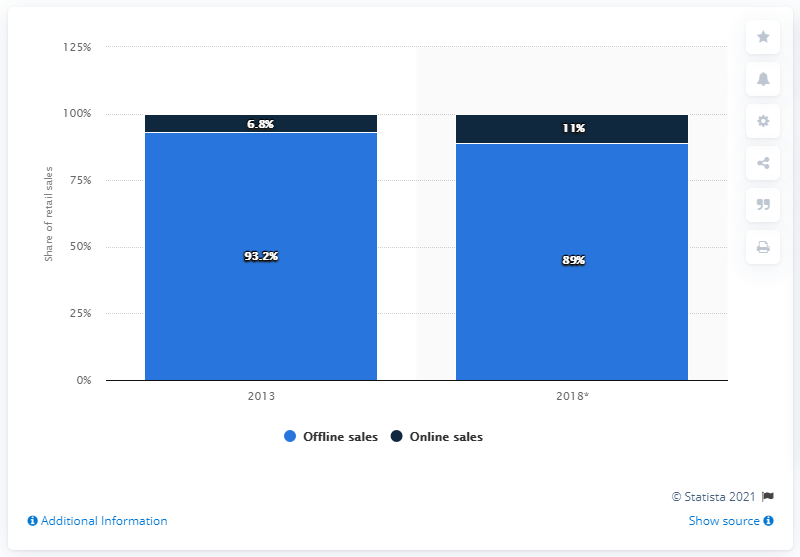

In [9]:
def take(split, n, seed):
    return split.shuffle(seed=seed).select(range(min(n, len(split))))


eval_set  = take(test_h,  CONFIG["N_EVAL"],  CONFIG["SEED"])
train_set = take(train_h, CONFIG["N_TRAIN"], CONFIG["SEED"])
val_set   = take(train_h, CONFIG["N_VAL"],   CONFIG["SEED"] + 1)

# --- leakage check -----------------------------------------------------------
# Same chart + same question appearing on both sides would silently inflate
# Step 2. Checking the pair, not just the question, because one chart carries
# several questions.
def keys(ds):
    return {(ex["query"], str(ex["label"])) for ex in ds}


overlap = keys(eval_set) & (keys(train_set) | keys(val_set))
assert not overlap, "LEAKAGE: %d eval items also appear in train/val" % len(overlap)
print("leakage check passed: no eval item appears in the fine-tune or val sets")

print("\neval  (from test) :", len(eval_set))
print("train (from train):", len(train_set))
print("val   (from train):", len(val_set))

ex = eval_set[0]
print("\n--- sample ---")
print("query :", ex["query"])
print("label :", ex["label"])
print("image :", ex["image"].size, ex["image"].mode)
ex["image"]


## 3. The prompt, and the one confound that matters

Both models are given the **identical** instruction. This matters more than it looks: a
vision-language model asked an open question will happily write a sentence, and a sentence scores
zero against an exact-match metric even when the number in it is right.

So the prompt pins the output format, and `extract_answer` is a *deliberately thin* parser — it
takes the last non-empty line and strips punctuation. It does **not** try to pull a number out of
prose.

**This is a real confound, and it is shared on purpose.** If one model obeys the format and the
other does not, Step 1 is partly measuring instruction-following rather than chart reading — which
is exactly the gap a 200-example fine-tune is likely to close. Step 2 is what tells you which you
were looking at. Keep both numbers in the report.

In [10]:
INSTRUCTION = (
    "Answer the question about the chart. "
    "Reply with the answer only - a number or a short phrase. "
    "Do not explain, do not write a sentence, do not repeat the question."
)


def build_question(query):
    return INSTRUCTION + "\n\nQuestion: " + query


def extract_answer(text):
    """Thin parser: last non-empty line, stripped. No prose mining by design."""
    lines = [ln.strip() for ln in str(text).strip().splitlines() if ln.strip()]
    if not lines:
        return ""
    out = lines[-1]
    out = re.sub(r"^(answer|the answer is)\s*[:\-]?\s*", "", out, flags=re.I)
    return out.strip(" .\"'")


print(build_question(eval_set[0]["query"]))


Answer the question about the chart. Reply with the answer only - a number or a short phrase. Do not explain, do not write a sentence, do not repeat the question.

Question: What is the average percentage share from 2013 to 2018 in offline sales of jewelry, watches, and accessories retail sector in Germany?


## 4. Model adapters

Qwen2.5-VL and Gemma 3 take different classes, different processors and different chat-template
conventions. Rather than hide that behind one generic wrapper that silently does the wrong thing
for one of them, each model gets an explicit adapter with the same three methods.

In [11]:
from transformers import Qwen2_5_VLForConditionalGeneration, Gemma3ForConditionalGeneration

BNB_4BIT = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=DTYPE,   # fp16 on T4, bf16 on L4/A100
)


class QwenAdapter:
    name = "Qwen2.5-VL-3B"
    model_id = CONFIG["QWEN_ID"]
    # LoRA must not touch the vision tower: it is frozen, and it is the
    # expensive half. "visual" is Qwen2.5-VL's vision-encoder prefix.
    vision_prefixes = ("visual",)

    def load(self, four_bit=False):
        self.processor = AutoProcessor.from_pretrained(
            self.model_id,
            min_pixels=CONFIG["QWEN_MIN_PIXELS"],
            max_pixels=CONFIG["QWEN_MAX_PIXELS"],
        )
        self.processor.tokenizer.padding_side = "left"   # correct for generation
        # device_map={"": 0} not "auto": on a small card "auto" silently
        # offloads layers to CPU RAM, which turns an OOM into a 20x slowdown
        # that looks like the model being slow rather than a config problem.
        # attn_implementation="eager": T4 has no flash-attn, and sdpa has had
        # correctness issues with interleaved image tokens.
        kw = dict(torch_dtype=DTYPE, device_map={"": 0}, attn_implementation="eager")
        if four_bit:
            kw["quantization_config"] = BNB_4BIT
        self.model = Qwen2_5_VLForConditionalGeneration.from_pretrained(self.model_id, **kw)
        return self

    def _messages(self, image, query):
        return [{"role": "user", "content": [
            {"type": "image"},
            {"type": "text", "text": build_question(query)},
        ]}]

    def prompt_text(self, query, add_generation_prompt=True):
        return self.processor.apply_chat_template(
            self._messages(None, query), tokenize=False,
            add_generation_prompt=add_generation_prompt)

    def collate_eval(self, batch):
        texts = [self.prompt_text(ex["query"]) for ex in batch]
        images = [ex["image"].convert("RGB") for ex in batch]
        return self.processor(text=texts, images=images,
                              return_tensors="pt", padding=True)


class GemmaAdapter:
    name = "Gemma 3 4B"
    model_id = CONFIG["GEMMA_ID"]
    vision_prefixes = ("vision_tower", "multi_modal_projector")

    def load(self, four_bit=False):
        self.processor = AutoProcessor.from_pretrained(self.model_id)
        self.processor.tokenizer.padding_side = "left"
        assert GEMMA_RUNNABLE, (
            "Refusing to load Gemma 3 without bf16: fp16 overflows its activations "
            "and the resulting score would be a bug, not a measurement. Use an L4 or A100."
        )
        kw = dict(torch_dtype=DTYPE, device_map={"": 0}, attn_implementation="eager")
        if four_bit:
            kw["quantization_config"] = BNB_4BIT
        self.model = Gemma3ForConditionalGeneration.from_pretrained(self.model_id, **kw)
        return self

    def _messages(self, image, query):
        return [{"role": "user", "content": [
            {"type": "image"},
            {"type": "text", "text": build_question(query)},
        ]}]

    def prompt_text(self, query, add_generation_prompt=True):
        return self.processor.apply_chat_template(
            self._messages(None, query), tokenize=False,
            add_generation_prompt=add_generation_prompt)

    def collate_eval(self, batch):
        texts = [self.prompt_text(ex["query"]) for ex in batch]
        images = [ex["image"].convert("RGB") for ex in batch]
        return self.processor(text=texts, images=images,
                              return_tensors="pt", padding=True)


ADAPTERS = {"qwen": QwenAdapter, "gemma": GemmaAdapter}
print("adapters:", list(ADAPTERS))


adapters: ['qwen', 'gemma']


In [12]:
@torch.no_grad()
def evaluate(adapter, dataset, label, batch_size=None, show_every=5):
    """Score an adapter on a dataset. Returns (relaxed_accuracy, per-example rows)."""
    bs = batch_size or CONFIG["BATCH_SIZE"]
    adapter.model.eval()

    # The KV cache is a pure speed optimisation: identical tokens out, far less
    # arithmetic, because each of the 32 generated tokens stops recomputing the
    # whole attention history. Set it explicitly rather than trusting a default
    # -- a model arriving here straight from fine-tuning has it switched off,
    # and the only symptom would be an evaluation that is quietly 3-5x slower.
    set_use_cache(adapter.model, True)
    torch.cuda.reset_peak_memory_stats()

    rows, t0, oom = [], time.time(), 0
    for start in range(0, len(dataset), bs):
        batch = [dataset[i] for i in range(start, min(start + bs, len(dataset)))]
        inputs = adapter.collate_eval(batch).to(adapter.model.device)

        try:
            out = adapter.model.generate(
                **inputs,
                max_new_tokens=CONFIG["MAX_NEW_TOKENS"],
                do_sample=False,                  # temperature 0, reproducible
                use_cache=True,                   # belt and braces: config may lie
                pad_token_id=adapter.processor.tokenizer.pad_token_id,
            )
        except torch.cuda.OutOfMemoryError:
            # One oversized chart should cost one example, not the whole run.
            torch.cuda.empty_cache()
            oom += 1
            for ex in batch:
                rows.append({"query": ex["query"], "gold": ex["label"],
                             "raw_output": "<OOM>", "pred": "", "correct": False})
            if oom > CONFIG["MAX_OOM_SKIPS"]:
                raise RuntimeError(
                    "%d OOM skips - this is not one awkward example, it is a "
                    "configuration that does not fit. Lower QWEN_MAX_PIXELS or "
                    "BATCH_SIZE." % oom)
            continue
        # Trim the prompt: generate() returns prompt + completion.
        trimmed = out[:, inputs["input_ids"].shape[1]:]
        decoded = adapter.processor.batch_decode(trimmed, skip_special_tokens=True)

        for ex, raw_out in zip(batch, decoded):
            pred = extract_answer(raw_out)
            rows.append({
                "query": ex["query"],
                "gold": ex["label"],
                "raw_output": raw_out.strip(),
                "pred": pred,
                "correct": relaxed_correct(pred, ex["label"]),
            })

        done = len(rows)
        if (start // bs) % show_every == 0 or done >= len(dataset):
            acc = 100.0 * sum(r["correct"] for r in rows) / done
            print("  [%s] %3d/%3d  running relaxed acc %5.2f" % (label, done, len(dataset), acc))

    acc = 100.0 * sum(r["correct"] for r in rows) / len(rows)
    print("  [%s] DONE  relaxed accuracy %.2f  (%.1fs, peak VRAM %.2f GB)"
          % (label, acc, time.time() - t0, vram_peak_gb()))
    if oom:
        print("  NOTE: %d example(s) scored 0 after an OOM, not after a wrong"
              " answer. This score is a floor; say so if you report it." % oom)
    return acc, rows


---
## Step 1 — evaluate both models cold

No training. One model at a time: two VLMs will not co-reside on a 24 GB card, so each is loaded,
scored, and freed before the next.

Loaded in **bf16, not 4-bit**, so these numbers are comparable to published figures. Step 2 will
re-measure in 4-bit so its before/after delta is measured within one precision.

In [13]:
STEP1_PATH = os.path.join(CONFIG["OUT_DIR"], "step1_scores.json")

step1 = {}
step1_rows = {}
skipped = {}

# Resume: a finished evaluation is a finished evaluation. Re-running the whole
# notebook after a crash should not repeat three minutes of work per model.
if CONFIG["RESUME"] and os.path.exists(STEP1_PATH):
    with open(STEP1_PATH) as fh:
        step1 = json.load(fh)
    if step1:
        print("Resuming: %s already scored in %s"
              % (", ".join(step1), STEP1_PATH))
        print("Delete that file to force a fresh run.\n")

for key, cls in ADAPTERS.items():
    print("\n" + "=" * 68)
    print("STEP 1:", cls.name, "|", cls.model_id,
          "| 4-bit NF4" if EVAL_4BIT else "| " + str(DTYPE))
    print("=" * 68)

    if key in step1:
        print("already scored: %.2f - skipping" % step1[key]["relaxed_accuracy"])
        continue

    if key == "gemma" and not GEMMA_RUNNABLE:
        skipped[key] = "no bf16 on this GPU - fp16 output would be NaN, not a score"
        print("SKIPPED:", skipped[key])
        print("Switch to an L4 runtime to include it.")
        continue

    require_vram(4.5 if EVAL_4BIT else 11.0, cls.name + " eval")
    adapter = cls().load(four_bit=EVAL_4BIT)
    acc, rows = evaluate(adapter, eval_set, cls.name)
    ok = sane_output(rows, cls.name)
    step1[key] = {"name": cls.name, "relaxed_accuracy": acc,
                  "peak_vram_gb": vram_peak_gb(), "output_sane": ok,
                  "precision": "4-bit NF4" if EVAL_4BIT else str(DTYPE)}
    step1_rows[key] = rows

    # None it first: free_memory() cannot drop the caller's reference, and the
    # next iteration loads a new model before rebinding this name.
    adapter = None
    free_memory()

    # Checkpoint after every model: a Colab disconnect part-way through should
    # not cost the model that already finished.
    with open(STEP1_PATH, "w") as fh:
        json.dump(step1, fh, indent=2)

if skipped:
    print("\n" + "=" * 68)
    print("INCOMPLETE COMPARISON - skipped:", ", ".join(skipped))
    print("Report what ran, and say what did not and why. A missing number is")
    print("a known gap; a wrong number is a wrong conclusion.")
    print("=" * 68)



STEP 1: Qwen2.5-VL-3B | Qwen/Qwen2.5-VL-3B-Instruct | 4-bit NF4
  vram: 11.6 GB free, ~4.5 GB needed for Qwen2.5-VL-3B eval


W1029 15:35:23.261169 8784 C:\D-Drive\Programs\Python\Python310\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
D:\Programs\Python\Python310\lib\site-packages\transformers\modeling_utils.py:5118: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:39.)
  _ = torch.empty(int(byte_count // 2), dtype=torch.float16, device=device, requires_grad=False)


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

D:\Programs\Python\Python310\lib\site-packages\transformers\models\qwen2_vl\image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


  [Qwen2.5-VL-3B]   1/150  running relaxed acc 100.00
  [Qwen2.5-VL-3B]   6/150  running relaxed acc 66.67


D:\Programs\Python\Python310\lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


  [Qwen2.5-VL-3B]  11/150  running relaxed acc 72.73
  [Qwen2.5-VL-3B]  16/150  running relaxed acc 75.00
  [Qwen2.5-VL-3B]  21/150  running relaxed acc 71.43
  [Qwen2.5-VL-3B]  26/150  running relaxed acc 69.23
  [Qwen2.5-VL-3B]  31/150  running relaxed acc 67.74
  [Qwen2.5-VL-3B]  36/150  running relaxed acc 63.89
  [Qwen2.5-VL-3B]  41/150  running relaxed acc 65.85
  [Qwen2.5-VL-3B]  46/150  running relaxed acc 65.22
  [Qwen2.5-VL-3B]  51/150  running relaxed acc 66.67
  [Qwen2.5-VL-3B]  56/150  running relaxed acc 66.07
  [Qwen2.5-VL-3B]  61/150  running relaxed acc 65.57
  [Qwen2.5-VL-3B]  66/150  running relaxed acc 66.67
  [Qwen2.5-VL-3B]  71/150  running relaxed acc 64.79
  [Qwen2.5-VL-3B]  76/150  running relaxed acc 63.16
  [Qwen2.5-VL-3B]  81/150  running relaxed acc 62.96
  [Qwen2.5-VL-3B]  86/150  running relaxed acc 62.79
  [Qwen2.5-VL-3B]  91/150  running relaxed acc 61.54
  [Qwen2.5-VL-3B]  96/150  running relaxed acc 60.42
  [Qwen2.5-VL-3B] 101/150  running relaxed acc

FileNotFoundError: [Errno 2] No such file or directory: 'bakeoff_out/5070-ti_qwen_1M\\step1_scores.json'

In [13]:
PUBLISHED_HUMAN_SPLIT = 78.96   # Qwen2.5-VL, human split, 5% tolerance

s1 = pd.DataFrame([
    {"model": v["name"],
     "relaxed accuracy (human split)": round(v["relaxed_accuracy"], 2),
     "peak VRAM (GB)": v["peak_vram_gb"]}
    for v in step1.values()
]).sort_values("relaxed accuracy (human split)", ascending=False).reset_index(drop=True)

print(s1.to_string(index=False))
print("\nReference: Qwen2.5-VL published human-split figure is %.2f." % PUBLISHED_HUMAN_SPLIT)
if EVAL_4BIT:
    print("CAUTION: Step 1 ran in 4-bit NF4 at reduced resolution. These scores")
    print("sit below the published bf16 figure for reasons that have nothing to")
    print("do with the model. Compare them to each other, not to 78.96.")
print("A large gap against our own measurement usually means the prompt or the answer")
print("parser, not the model. Check raw_output below before believing it.")
s1


        model  relaxed accuracy (human split)  peak VRAM (GB)
Qwen2.5-VL-3B                           64.00            3.53
   Gemma 3 4B                           41.33            7.82

Reference: Qwen2.5-VL published human-split figure is 78.96.
CAUTION: Step 1 ran in 4-bit NF4 at reduced resolution. These scores
sit below the published bf16 figure for reasons that have nothing to
do with the model. Compare them to each other, not to 78.96.
A large gap against our own measurement usually means the prompt or the answer
parser, not the model. Check raw_output below before believing it.


,model,relaxed accuracy (human split),peak VRAM (GB)
0,Qwen2.5-VL-3B,64.00,3.53
1,Gemma 3 4B,41.33,7.82


### Look at the raw output before trusting the score

The single most common way this comparison goes wrong: one model obeys "answer only" and the
other writes a sentence. That shows up as a capability gap and is not one. Read ten of each.

In [14]:
if not step1_rows:
    print("No per-example rows in memory - Step 1 was resumed from disk rather")
    print("than re-run. Scores are intact; only the raw outputs are missing.")
    print("Delete step1_scores.json and re-run Step 1 to inspect them.")

for key in step1_rows:
    print("\n" + "-" * 68)
    print(step1[key]["name"], "- 6 sample outputs")
    print("-" * 68)
    for r in step1_rows[key][:6]:
        flag = "OK " if r["correct"] else "XX "
        print("%s gold=%-22s pred=%-22s raw=%r"
              % (flag, str(r["gold"])[:22], r["pred"][:22], r["raw_output"][:60]))

# How often did each model produce something that was not a bare answer?
print("\nVerbose-output rate (raw output longer than 40 chars):")
for key, rows in step1_rows.items():
    verbose = sum(1 for r in rows if len(r["raw_output"]) > 40)
    print("  %-16s %5.1f%%  <- high here means Step 1 is partly measuring format-following"
          % (step1[key]["name"], 100.0 * verbose / len(rows)))


No per-example rows in memory - Step 1 was resumed from disk rather
than re-run. Scores are intact; only the raw outputs are missing.
Delete step1_scores.json and re-run Step 1 to inspect them.

Verbose-output rate (raw output longer than 40 chars):


---
## Step 2 — a 200-example fine-tune, and does it move

**The question this step answers:** is a low Step 1 score *missing capability* (trainable) or a
*vision encoder that cannot resolve the tick labels* (not trainable)? Those look identical in
Step 1 and opposite in Step 2.

QLoRA, 4-bit, **vision encoder frozen** — LoRA targets the language-model linear layers only.
Both models are re-scored in 4-bit *before* training, so the delta is measured within one
precision rather than across two.

**Which models get trained** is decided below from the Step 1 result. Default: train every model
within 15 points of the best, because the cheapest way to get this decision wrong is to eliminate
a model on a score that was really a formatting artefact.

In [15]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from torch.utils.data import DataLoader
from transformers import get_cosine_schedule_with_warmup


def find_lora_targets(model, vision_prefixes):
    """Full paths of every nn.Linear in the language model, vision tower excluded.

    This returns FULL module paths, not suffixes, and that distinction is the
    whole point. PEFT resolves a list of target_modules with

        key == target or key.endswith("." + target)

    so handing it ["q_proj", ...] re-matches every identically-named layer in
    the vision encoder and silently unfreezes it -- filtering during the walk
    buys nothing if the full name is then discarded. Full paths match by
    equality, so what this function excludes stays excluded.
    """
    targets = []
    for full_name, module in model.named_modules():
        if not isinstance(module, torch.nn.Linear):
            continue
        if any(p in full_name for p in vision_prefixes):
            continue
        if "lm_head" in full_name:
            continue
        targets.append(full_name)
    assert targets, "no LoRA targets found - check vision_prefixes for this model"
    return sorted(targets)


W1029 06:33:58.852738 1172 C:\D-Drive\Programs\Python\Python310\Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


In [16]:
def make_train_collator(adapter):
    """Build (input_ids, labels) with the prompt masked out.

    Only the assistant span carries loss. Training on the prompt teaches the
    model to predict the question, which is not the task.
    """
    tok = adapter.processor.tokenizer
    seen = {"first": True}

    def collate(batch):
        texts, images, pairs = [], [], []
        for ex in batch:
            prompt = adapter.prompt_text(ex["query"], add_generation_prompt=True)
            answer = str(ex["label"][0] if isinstance(ex["label"], list) else ex["label"])
            texts.append(prompt + answer + tok.eos_token)
            images.append(ex["image"].convert("RGB"))
            pairs.append((prompt, answer))

        # Right padding for training (left padding is a generation-only concern).
        old_side, tok.padding_side = tok.padding_side, "right"
        enc = adapter.processor(text=texts, images=images, return_tensors="pt", padding=True)
        tok.padding_side = old_side

        labels = enc["input_ids"].clone()
        labels[labels == tok.pad_token_id] = -100

        # Mask the prompt span -- measured AFTER the processor runs.
        #
        # Tokenising the prompt text counts the image placeholder as ONE token.
        # The real sequence carries the expanded image span: 160 tokens for Qwen
        # at 0.50M pixels, 256 for Gemma. Masking by the text length therefore
        # leaves the entire image span supervised and trains the model to emit
        # image tokens -- roughly 98% of the loss lands on them instead of the
        # answer. Run the processor on the prompt alone to get the true length.
        for i, ((prompt, answer), img) in enumerate(zip(pairs, images)):
            p_enc = adapter.processor(text=[prompt], images=[img], return_tensors="pt")
            labels[i, :p_enc["input_ids"].shape[1]] = -100

        supervised = (labels != -100).sum(dim=1)
        assert (supervised > 0).all(), \
            "an example has no supervised tokens - prompt longer than max length?"

        # The supervised span must be the answer plus EOS and nothing else.
        # This is the assertion that would have caught the bug above on the
        # first batch rather than after a 45-minute run.
        for i, (prompt, answer) in enumerate(pairs):
            expect = len(tok(answer, add_special_tokens=False)["input_ids"]) + 1
            got = int(supervised[i])
            assert got <= expect + 5, (
                "example %d supervises %d tokens but its answer is only %d. "
                "The prompt mask is misaligned -- almost certainly image-token "
                "expansion, which trains the model to predict image tokens."
                % (i, got, expect))

        if seen["first"]:
            seen["first"] = False
            print("  label check: %d tokens supervised per example on average"
                  " (answers are short, so this should be single digits)"
                  % int(supervised.float().mean()))

        enc["labels"] = labels
        return enc

    return collate

In [17]:
def finetune(cls, train_ds, val_ds):
    """Load 4-bit, attach LoRA, train, return the adapter with the tuned model."""
    adapter = cls().load(four_bit=True)
    model = prepare_model_for_kbit_training(
        adapter.model,
        use_gradient_checkpointing=CONFIG["GRAD_CHECKPOINTING"],
    )
    # Must happen before the first forward pass, not just before training.
    print("  use_cache=False on:", ", ".join(set_use_cache(model, False)))
    if CONFIG["GRAD_CHECKPOINTING"]:
        # reentrant=False is required when only some params need grad, which is
        # exactly the LoRA case. The default silently drops the backward pass.
        model.gradient_checkpointing_enable(
            gradient_checkpointing_kwargs={"use_reentrant": False})
        model.enable_input_require_grads()
        print("  gradient checkpointing on (slower per step, much lower VRAM)")

    targets = find_lora_targets(model, cls.vision_prefixes)
    kinds = sorted({t.split(".")[-1] for t in targets})
    print("  LoRA targets: %d modules, kinds %s" % (len(targets), kinds))

    model = get_peft_model(model, LoraConfig(
        r=CONFIG["LORA_R"], lora_alpha=CONFIG["LORA_ALPHA"],
        lora_dropout=CONFIG["LORA_DROPOUT"],
        target_modules=targets, bias="none", task_type="CAUSAL_LM",
    ))
    model.print_trainable_parameters()

    # PEFT silently ignores a target it cannot resolve, so confirm it wrapped
    # exactly what we asked for. A mismatch means the naming assumption broke.
    wrapped = len({n.rsplit(".lora_", 1)[0] for n, _ in model.named_parameters()
                   if ".lora_" in n})
    assert wrapped == len(targets), (
        "PEFT wrapped %d modules but %d were requested - target names did not "
        "resolve as expected." % (wrapped, len(targets)))

    # Confirm the vision encoder really is frozen -- the whole cost model
    # depends on it, and a silent unfreeze shows up only as a slow run.
    vision_trainable = [n for n, p in model.named_parameters()
                        if p.requires_grad and any(v in n for v in cls.vision_prefixes)]
    assert not vision_trainable, (
        "vision encoder is trainable, which breaks the cost model this project "
        "is built on. %d such params, e.g. %s. find_lora_targets must return "
        "FULL module paths; bare suffixes let PEFT re-match the vision tower."
        % (len(vision_trainable), vision_trainable[:2]))
    print("  vision encoder frozen: confirmed")

    loader = DataLoader(train_ds, batch_size=CONFIG["MICRO_BATCH"], shuffle=True,
                        collate_fn=make_train_collator(adapter))
    steps = (len(loader) // CONFIG["GRAD_ACCUM"]) * CONFIG["EPOCHS"]
    total_steps = max(steps, 1)
    print("  %d examples, %d micro-batches/epoch, %d optimiser steps total"
          % (len(train_ds), len(loader), total_steps))
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=CONFIG["LR"])
    sched = get_cosine_schedule_with_warmup(opt, int(0.03 * steps) + 1, max(steps, 1))

    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    model.train()
    gstep = 0
    oom_steps = 0
    for epoch in range(CONFIG["EPOCHS"]):
        running = 0.0
        for i, batch in enumerate(loader):
            batch = {k: v.to(model.device) for k, v in batch.items()}
            try:
                loss = model(**batch).loss / CONFIG["GRAD_ACCUM"]
                loss.backward()
            except torch.cuda.OutOfMemoryError:
                # Skip the batch, keep the run. Gradients so far are discarded
                # because a half-accumulated step is not a step.
                oom_steps += 1
                opt.zero_grad(set_to_none=True)
                del batch
                gc.collect()
                torch.cuda.empty_cache()
                if oom_steps > CONFIG["MAX_OOM_SKIPS"]:
                    raise RuntimeError(
                        "%d OOM skips during training - the configuration does "
                        "not fit. Lower QWEN_MAX_PIXELS or MICRO_BATCH."
                        % oom_steps)
                print("    OOM on batch %d - skipped (%d/%d allowed)"
                      % (i, oom_steps, CONFIG["MAX_OOM_SKIPS"]))
                continue
            running += loss.item() * CONFIG["GRAD_ACCUM"]
            # Heartbeat on the very first batch: it proves the loop is alive and
            # gives the per-batch cost, from which everything else follows.
            if epoch == 0 and i == 0:
                print("    first micro-batch in %.1fs  (%d per optimiser step, "
                      "%d steps total -> ~%.0f min)"
                      % (time.time() - t0, CONFIG["GRAD_ACCUM"], total_steps,
                         (time.time() - t0) * total_steps
                         * CONFIG["GRAD_ACCUM"] / 60.0))

            if (i + 1) % CONFIG["GRAD_ACCUM"] == 0:
                torch.nn.utils.clip_grad_norm_(
                    [p for p in model.parameters() if p.requires_grad], 1.0)
                opt.step(); sched.step(); opt.zero_grad()
                gstep += 1
                if gstep == 1 or gstep % 5 == 0 or gstep == total_steps:
                    el = time.time() - t0
                    eta = (el / gstep) * (total_steps - gstep) / 60.0
                    print("    epoch %d  step %2d/%d  loss %.4f  (%.0fs elapsed,"
                          " ~%.0f min left)"
                          % (epoch + 1, gstep, total_steps,
                             running / (i + 1), el, eta))
        print("  epoch %d mean loss %.4f" % (epoch + 1, running / len(loader)))

    print("  trained in %.1f min, peak VRAM %.2f GB" % ((time.time() - t0) / 60, vram_peak_gb()))
    if oom_steps:
        print("  NOTE: %d batch(es) were skipped on OOM - the model saw fewer"
              " than %d examples." % (oom_steps, CONFIG["N_TRAIN"]))
    # Restore it here too. evaluate() sets it as well, so this is redundant by
    # design: the model is also returned to the caller, and handing back an
    # object left in a training configuration is how the next bug starts.
    model.gradient_checkpointing_disable()
    set_use_cache(model, True)
    model.eval()
    adapter.model = model
    return adapter, (time.time() - t0) / 60


In [18]:
# Which candidates are worth training?
assert step1, "Step 1 produced no scores - nothing to fine-tune."

best = max(v["relaxed_accuracy"] for v in step1.values())

if CONFIG["TRAIN_BOTH"]:
    candidates = list(step1)
    why = "TRAIN_BOTH is set - every model scored in Step 1 gets fine-tuned."
else:
    win = CONFIG["CANDIDATE_WINDOW"]
    candidates = [k for k, v in step1.items()
                  if v["relaxed_accuracy"] >= best - win]
    why = "within %.0f points of the leader" % win

if CONFIG["SMOKE_TEST"]:
    # Deliberately NOT narrowed to one model: the point of the rehearsal is to
    # prove both fit, including the release between them. Trimming it here
    # would skip exactly the step most likely to fail.
    why = "SMOKE_TEST - every candidate, tiny data, to prove the path fits."

if len(step1) < len(ADAPTERS):
    print("NOTE: only %d of %d models were scored in Step 1." % (len(step1), len(ADAPTERS)))
    print("Step 2 can only speak about what Step 1 measured.")
    print()

print("Step 1 best: %.2f  (%s)" % (best, why))
for k, v in step1.items():
    mark = "TRAIN" if k in candidates else "skip "
    print("  %s %-16s %6.2f" % (mark, v["name"], v["relaxed_accuracy"]))

if len(candidates) < len(step1):
    print("\nA model is being skipped. Step 1 alone cannot tell a capability gap")
    print("from a vision encoder that cannot resolve tick labels, and those two")
    print("have different answers. Set CONFIG[\'TRAIN_BOTH\'] = True to measure it.")
# candidates = ["qwen"]   # <- or name them explicitly


Step 1 best: 64.00  (TRAIN_BOTH is set - every model scored in Step 1 gets fine-tuned.)
  TRAIN Qwen2.5-VL-3B     64.00
  TRAIN Gemma 3 4B        41.33


In [19]:
# import gc, sys, torch

# # 1. diagnose
# print("allocated %.2f GB | free %.2f GB"
#       % (torch.cuda.memory_allocated()/1e9, torch.cuda.mem_get_info()[0]/1e9))
# for name, val in list(globals().items()):
#     if isinstance(val, torch.nn.Module):
#         print("  module held by global:", name)
#     elif hasattr(val, "model") and isinstance(getattr(val, "model", None), torch.nn.Module):
#         print("  adapter held by global:", name)

# # 2. release
# for name in ("base", "tuned", "adapter", "model", "peft_model"):
#     if name in globals():
#         globals()[name] = None
# sys.last_traceback = sys.last_value = sys.last_type = None
# for d in ("Out", "_oh"):
#     if isinstance(globals().get(d), dict):
#         globals()[d].clear()
# for v in ("_", "__", "___"):
#     globals()[v] = None

# gc.collect(); torch.cuda.empty_cache(); torch.cuda.synchronize()
# print("after: allocated %.2f GB | free %.2f GB"
#       % (torch.cuda.memory_allocated()/1e9, torch.cuda.mem_get_info()[0]/1e9))

In [20]:
# import gc, torch, collections
# sizes, total = collections.Counter(), 0
# for obj in gc.get_objects():
#     try:
#         if torch.is_tensor(obj) and obj.is_cuda:
#             n = obj.numel() * obj.element_size()
#             total += n
#             sizes[tuple(obj.shape)] += n
#     except Exception:
#         pass
# print("live cuda tensors: %.2f GB" % (total / 1e9))
# for shape, n in sizes.most_common(8):
#     print("  %-30s %.3f GB" % (str(shape), n / 1e9))

In [21]:
STEP2_PATH = os.path.join(CONFIG["OUT_DIR"], "step2_scores.json")

step2 = {}
if CONFIG["RESUME"] and os.path.exists(STEP2_PATH):
    with open(STEP2_PATH) as fh:
        step2 = json.load(fh)
    if step2:
        print("Resuming: %s already fine-tuned.\n" % ", ".join(step2))

for key in candidates:
    if key in step2:
        print("already fine-tuned: %s (delta %+.2f) - skipping"
              % (step2[key]["name"], step2[key]["delta"]))
        continue

    cls = ADAPTERS[key]
    print("\n" + "=" * 68)
    print("STEP 2:", cls.name)
    print("=" * 68)

    # (a) The baseline the delta is measured against. It has to match the
    # fine-tuned model's precision: comparing a bf16 cold score against a 4-bit
    # tuned score folds quantisation loss into the training gain and reports
    # the sum of the two as though it were the gain alone.
    #
    # But when Step 1 already ran 4-bit -- which it does on any card under
    # 14 GB -- that baseline is already measured, on the same model, data, seed
    # and resolution, with greedy decoding. Re-running it spends three minutes
    # recomputing a number we are holding.
    reused = step1.get(key, {}).get("precision") == "4-bit NF4"
    if reused:
        pre_acc = step1[key]["relaxed_accuracy"]
        print("\n-- 4-bit pre-finetune baseline: reusing Step 1 (%.2f) --" % pre_acc)
        print("  Step 1 ran 4-bit NF4 at this resolution, so it IS this baseline.")
    else:
        print("\n-- 4-bit pre-finetune baseline --")
        print("  Step 1 ran %s, which cannot be the baseline for a 4-bit"
              % step1.get(key, {}).get("precision", "another precision"))
        print("  fine-tune. Measuring the 4-bit starting point separately.")
        require_vram(4.5, cls.name + " 4-bit baseline")
        base = cls().load(four_bit=True)
        pre_acc, _ = evaluate(base, eval_set, cls.name + " 4bit/pre")
        base = None
        free_memory()

    # (b) fine-tune
    print("\n-- fine-tuning on %d examples --" % len(train_set))
    require_vram(6.0, cls.name + " fine-tune")
    tuned, minutes = finetune(cls, train_set, val_set)

    # (c) re-score
    print("\n-- post-finetune --")
    post_acc, post_rows = evaluate(tuned, eval_set, cls.name + " 4bit/post")

    tuned.model.save_pretrained(os.path.join(CONFIG["OUT_DIR"], "adapter_" + key))
    step2[key] = {
        "name": cls.name,
        "step1_cold": step1[key]["relaxed_accuracy"],
        "pre_4bit": pre_acc,
        "pre_4bit_source": "reused from Step 1" if reused else "measured in Step 2",
        "post_4bit": post_acc,
        "delta": post_acc - pre_acc,
        "train_minutes": round(minutes, 1),
        "peak_vram_gb": vram_peak_gb(),
    }
    tuned = None
    free_memory()

    # Checkpoint inside the loop. Fine-tuning is the longest unbroken stretch of
    # GPU load in this notebook and the most likely place to lose the machine;
    # a crash during the second model must not cost the first model's result.
    with open(STEP2_PATH, "w") as fh:
        json.dump(step2, fh, indent=2)
    print("  checkpointed ->", STEP2_PATH)

print("\nsaved", STEP2_PATH)



STEP 2: Qwen2.5-VL-3B

-- 4-bit pre-finetune baseline: reusing Step 1 (64.00) --
  Step 1 ran 4-bit NF4 at this resolution, so it IS this baseline.

-- fine-tuning on 200 examples --
  vram: 11.6 GB free, ~6.0 GB needed for Qwen2.5-VL-3B fine-tune


D:\Programs\Python\Python310\lib\site-packages\transformers\modeling_utils.py:5118: UserWarning: expandable_segments not supported on this platform (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\c10/cuda/CUDAAllocatorConfig.h:39.)
  _ = torch.empty(int(byte_count // 2), dtype=torch.float16, device=device, requires_grad=False)


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

  use_cache=False on: text_config, generation_config
  gradient checkpointing on (slower per step, much lower VRAM)
  LoRA targets: 252 modules, kinds ['down_proj', 'gate_proj', 'k_proj', 'o_proj', 'q_proj', 'up_proj', 'v_proj']
trainable params: 29,933,568 || all params: 3,784,556,544 || trainable%: 0.7909
  vision encoder frozen: confirmed
  200 examples, 200 micro-batches/epoch, 50 optimiser steps total
  label check: 4 tokens supervised per example on average (answers are short, so this should be single digits)


D:\Programs\Python\Python310\lib\site-packages\transformers\models\qwen2_vl\image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(
D:\Programs\Python\Python310\lib\site-packages\bitsandbytes\backends\cuda\ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(


    first micro-batch in 1.5s  (8 per optimiser step, 50 steps total -> ~10 min)
    epoch 1  step  1/50  loss 0.3067  (14s elapsed, ~11 min left)
    epoch 1  step  5/50  loss 0.4357  (68s elapsed, ~10 min left)
    epoch 1  step 10/50  loss 0.4000  (132s elapsed, ~9 min left)
    epoch 1  step 15/50  loss 0.3963  (196s elapsed, ~8 min left)
    epoch 1  step 20/50  loss 0.4066  (263s elapsed, ~7 min left)
    epoch 1  step 25/50  loss 0.4600  (328s elapsed, ~5 min left)
  epoch 1 mean loss 0.4600
    epoch 2  step 30/50  loss 0.2747  (394s elapsed, ~4 min left)
    epoch 2  step 35/50  loss 0.2387  (461s elapsed, ~3 min left)
    epoch 2  step 40/50  loss 0.3079  (523s elapsed, ~2 min left)
    epoch 2  step 45/50  loss 0.2693  (589s elapsed, ~1 min left)
    epoch 2  step 50/50  loss 0.2985  (655s elapsed, ~0 min left)
  epoch 2 mean loss 0.2985
  trained in 10.9 min, peak VRAM 5.72 GB

-- post-finetune --
  [Qwen2.5-VL-3B 4bit/post]   1/150  running relaxed acc 100.00
  [Qwen2.5-VL

Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

  use_cache=False on: text_config, generation_config
  gradient checkpointing on (slower per step, much lower VRAM)
  LoRA targets: 238 modules, kinds ['down_proj', 'gate_proj', 'k_proj', 'o_proj', 'q_proj', 'up_proj', 'v_proj']
trainable params: 29,802,496 || all params: 4,329,881,968 || trainable%: 0.6883
  vision encoder frozen: confirmed
  200 examples, 200 micro-batches/epoch, 50 optimiser steps total
  label check: 2 tokens supervised per example on average (answers are short, so this should be single digits)
    first micro-batch in 3.8s  (8 per optimiser step, 50 steps total -> ~25 min)
    epoch 1  step  1/50  loss 10.1817  (27s elapsed, ~22 min left)
    epoch 1  step  5/50  loss 7.9927  (133s elapsed, ~20 min left)
    epoch 1  step 10/50  loss 4.9748  (265s elapsed, ~18 min left)
    epoch 1  step 15/50  loss 3.7187  (397s elapsed, ~15 min left)
    epoch 1  step 20/50  loss 3.0377  (529s elapsed, ~13 min left)
    epoch 1  step 25/50  loss 2.6441  (662s elapsed, ~11 min le

In [22]:
s2 = pd.DataFrame([
    {"model": v["name"],
     "cold (step 1)": round(v["step1_cold"], 2),
     "pre 4-bit": round(v["pre_4bit"], 2),
     "post 4-bit": round(v["post_4bit"], 2),
     "delta": round(v["delta"], 2),
     "train min": v["train_minutes"]}
    for v in step2.values()
]).sort_values("delta", ascending=False).reset_index(drop=True)

print(s2.to_string(index=False))
print("\nThe delta column is the one that matters. Compare 'post 4-bit' against")
print("'pre 4-bit', never against 'cold bf16' -- that would mix a quantisation")
print("effect into the training effect.")
s2


        model  cold (step 1)  pre 4-bit  post 4-bit  delta  train min
Qwen2.5-VL-3B          64.00      64.00       67.33   3.33       10.9
   Gemma 3 4B          41.33      41.33       41.33   0.00       22.1

The delta column is the one that matters. Compare 'post 4-bit' against
'pre 4-bit', never against 'cold bf16' -- that would mix a quantisation
effect into the training effect.


,model,cold (step 1),pre 4-bit,post 4-bit,delta,train min
0,Qwen2.5-VL-3B,64.00,64.00,67.33,3.33,10.9
1,Gemma 3 4B,41.33,41.33,41.33,0.00,22.1


---
## Step 3 — choose

The rule, stated before the numbers came in:

| Observation | Reading |
|---|---|
| Delta ≥ `MIN_MEANINGFUL_DELTA` | The model can be taught this task. A real candidate. |
| Delta ≈ 0 from a **low** base | The ceiling is the vision encoder, not knowledge. 1,200 examples will not fix it. |
| Delta ≈ 0 from a **high** base | Saturated. Headroom is elsewhere — schema, abstention, evidence. |
| Delta negative | Check the collator and the masking before concluding anything. |

**On significance:** at n=150 the bootstrap 95% interval is roughly ±6 points. A delta under that
is suggestive, not significant, and the notebook labels it as such. Raise `N_EVAL` before treating
a small gap as real.

In [23]:
import math

N = len(eval_set)
CI_HALF = 1.96 * math.sqrt(0.25 / N) * 100   # worst-case (p=0.5) half-width, points
print("n = %d  ->  95%% CI half-width is about +-%.1f points\n" % (N, CI_HALF))

verdicts = []
for key, v in step2.items():
    d, pre, post = v["delta"], v["pre_4bit"], v["post_4bit"]
    if d < -1.0:
        verdict, why = "INVESTIGATE", "went backwards - check label masking and the collator"
    elif d >= CONFIG["MIN_MEANINGFUL_DELTA"]:
        sig = "significant" if d >= CI_HALF else "suggestive, below the CI half-width"
        verdict, why = "TRAINABLE", "moved +%.1f points (%s)" % (d, sig)
    elif pre >= 75.0:
        verdict, why = "SATURATED", "flat from a high base - headroom is not in this metric"
    else:
        verdict, why = "CAPPED", "flat from a low base (%.1f) - suspect the vision encoder" % pre
    verdicts.append({"model": v["name"], "pre": round(pre, 2), "post": round(post, 2),
                     "delta": round(d, 2), "verdict": verdict, "reading": why})

v3 = pd.DataFrame(verdicts).sort_values("delta", ascending=False).reset_index(drop=True)
print(v3.to_string(index=False))

trainable = [r for r in verdicts if r["verdict"] == "TRAINABLE"]
print("\n" + "=" * 68)
if trainable:
    pick = max(trainable, key=lambda r: r["post"])
    print("RECOMMENDATION: %s" % pick["model"])
    print("  highest post-finetune score (%.2f) among models that demonstrably learn" % pick["post"])
    if len(trainable) > 1:
        other = [r for r in trainable if r is not pick]
        print("  note: %s also learns - if its delta is larger, that is the more"
              % ", ".join(r["model"] for r in other))
        print("  interesting report result even if its absolute score is lower")
else:
    pick = max(verdicts, key=lambda r: r["post"])
    print("RECOMMENDATION: %s (on absolute score - nothing demonstrated real headroom)" % pick["model"])
    print("  Before accepting this: 200 examples and %d epochs is a small test." % CONFIG["EPOCHS"])
    print("  Raise N_TRAIN to 500 and re-run Step 2 before concluding the task is untrainable.")
print("=" * 68)

with open(os.path.join(CONFIG["OUT_DIR"], "step3_decision.json"), "w") as fh:
    json.dump({"n_eval": N, "ci_half_width": round(CI_HALF, 2),
               "verdicts": verdicts, "recommended": pick["model"]}, fh, indent=2)


n = 150  ->  95% CI half-width is about +-8.0 points

        model   pre  post  delta   verdict                                                  reading
Qwen2.5-VL-3B 64.00 67.33   3.33 TRAINABLE  moved +3.3 points (suggestive, below the CI half-width)
   Gemma 3 4B 41.33 41.33   0.00    CAPPED flat from a low base (41.3) - suspect the vision encoder

RECOMMENDATION: Qwen2.5-VL-3B
  highest post-finetune score (67.33) among models that demonstrably learn


In [24]:
# Everything the report needs, in one place.
summary = {
    "environment": ENVIRONMENT,
    "config": CONFIG,
    "n_eval": len(eval_set), "n_train": len(train_set),
    "split": "human-written only (human_or_machine == 0)",
    "metric": "relaxed accuracy, 5% numeric tolerance, exact match for text",
    "step1": step1, "step2": step2,
    "decision": {"recommended": pick["model"], "verdicts": verdicts},
}
path = os.path.join(CONFIG["OUT_DIR"], "bakeoff_summary.json")
with open(path, "w") as fh:
    json.dump(summary, fh, indent=2, default=str)
print("wrote", path)

# Per-example predictions, one file per model. Step 1 already wrote these as
# it went; this re-writes whatever is in memory and reports the rest, so the
# cell is correct whether Step 1 ran or was resumed from disk.
for key, rows in step1_rows.items():
    out = os.path.join(CONFIG["OUT_DIR"], "step1_predictions_%s.csv" % key)
    pd.DataFrame(rows).to_csv(out, index=False)
    print("wrote", out)

on_disk = sorted(f for f in os.listdir(CONFIG["OUT_DIR"])
                 if f.startswith("step1_predictions_"))
missing = [k for k in step1 if "step1_predictions_%s.csv" % k not in on_disk]

if not step1_rows:
    print("No per-example rows in memory - Step 1 was resumed from disk.")
    print("Scores and the summary are complete; only the CSVs depend on rows.")
if on_disk:
    print("prediction files present:", ", ".join(on_disk))
if missing:
    print("NOTE: no predictions on disk for %s. Delete step1_scores.json and"
          % ", ".join(missing))
    print("re-run Step 1 if you need them for error analysis.")

wrote bakeoff_out\5070-ti_4bit\bakeoff_summary.json
No per-example rows in memory - Step 1 was resumed from disk.
Scores and the summary are complete; only the CSVs depend on rows.
NOTE: no predictions on disk for qwen, gemma. Delete step1_scores.json and
re-run Step 1 if you need them for error analysis.


---
## What this notebook does not settle

Worth writing into the report alongside the numbers, because a reviewer will ask:

- **200 examples and 2 epochs is a smoke test.** A flat delta is evidence that the model is hard to
  move, not proof that it cannot be moved. The Week 2 runs are the real measurement.
- **The answer parser is thin on purpose**, so a verbose model is penalised. That penalty is part
  of what fine-tuning removes, which is why Step 2 can show a large delta that is mostly format
  rather than chart reading. The verbose-output rate printed after Step 1 is how you tell.
- **n=150 gives roughly ±6 points.** Two models four points apart are tied.
- **Quantisation is held constant within Step 2** (4-bit pre and post) but Step 1 is bf16. Do not
  compare a Step 1 number to a Step 2 number.
- **Only relaxed accuracy is measured here.** Schema validity, abstention and evidence grounding —
  the other three metrics in the proposal — need the full output schema and are out of scope for a
  base-model bake-off.
- **Licences travel with the choice.** Qwen2.5-VL is Apache-2.0. Gemma carries Google's Terms of
  Use, which bind any adapter trained on it as a model derivative. ChartQA's own GPL-3.0 tag sits
  underneath both.
